# NeuroDB
### A relational database for computational neuroscience

Julia (Jiahe) Yi · DSCI 551 · Fall 2026

NeuroDB integrates publicly available experimental observations, event timing records and computational model outputs into a reusable MySQL database.

This project demonstrates reproducible data integration, relational database design, meaningful query workloads and empirical evaluation of alternative physical designs.

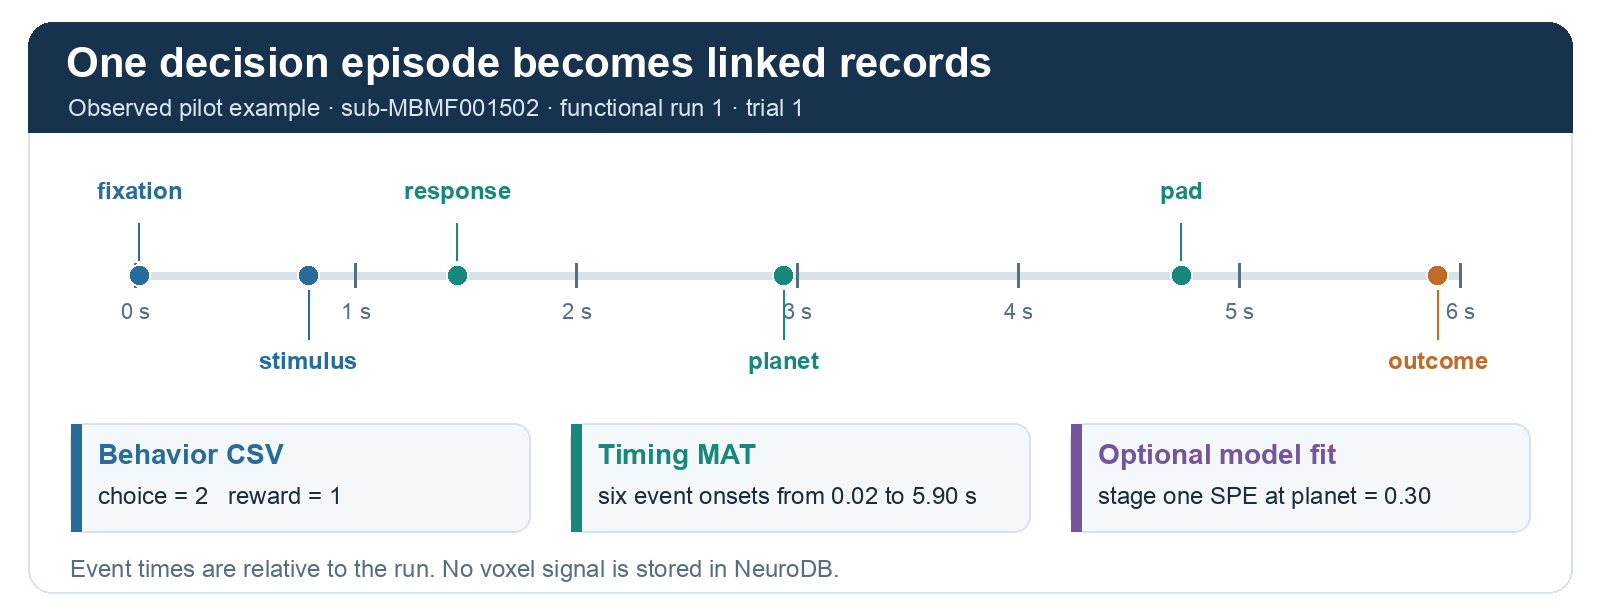


In [1]:
from pathlib import Path
import sys, json
ROOT = Path.cwd() if (Path.cwd() / 'neurodb').is_dir() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image, HTML
from neurodb.server import start
from neurodb.queries import query, execute, defaults, QUERIES
from neurodb.benchmark import summary
start()
pd.set_option('display.max_columns', 16)
pd.set_option('display.max_colwidth', 75)
display(HTML('<style>.dataframe{font-size:13px}.jp-OutputArea-output{overflow:auto}pre{white-space:pre-wrap}</style>'))
display(query('SELECT VERSION() AS mysql_version, CURRENT_USER() AS demo_user, DATABASE() AS database_name'))

MySQL 8.4.11 ready


,mysql_version,demo_user,database_name
0,8.4.11,neurodb_demo@localhost,neurodb


## Acquisition and validation

**Data pipeline**

Public source files → Identifier reconciliation → Data transformation → Validation → MySQL

Behavioral observations are stored in CSV files, while experimental event timestamps are stored in MATLAB files. The same experimental run can have different identifiers across these sources. The loader resolves these mismatches before combining the records.

Source file versions and SHA-256 checksums allow the imported data to be traced back to the original files. Unique keys and transactional upserts prevent duplicate records when ingestion is repeated. Each loading attempt is recorded in an audit table.

In [2]:
manifest = json.loads((ROOT / 'data/raw/manifest.json').read_text())
display(pd.DataFrame([{'source_participant_pairs': len(manifest['participants']),
                       'pinned_source_files': len(manifest['sources']),
                       'openneuro_snapshot': manifest['openneuro_version']}]))
display(query('SELECT inclusion_status, COUNT(*) AS participants FROM participants GROUP BY inclusion_status'))
display(query("SELECT exclusion_reason,COUNT(*) AS participants FROM participants WHERE inclusion_status='excluded' GROUP BY exclusion_reason"))
display(query('SELECT ingestion_id,transform_version,executed_at,status,message FROM ingestion_runs ORDER BY ingestion_id DESC LIMIT 4'))

,source_participant_pairs,pinned_source_files,openneuro_snapshot
0,189,378,1.0.5


,inclusion_status,participants
0,validated,189


,exclusion_reason,participants


,ingestion_id,transform_version,executed_at,status,message
0,3,neurodb-1.0.0,2026-11-21 20:53:48.865470,passed,189 participants validated
1,2,neurodb-1.0.0,2026-11-21 20:53:30.885311,passed,189 participants validated
2,1,neurodb-1.0.0,2026-11-21 20:49:34.506622,passed,90 participants validated


In [3]:
display(query("""SELECT p.bids_label,r.run_type,r.behavior_run_number,r.run_number,
COUNT(t.trial_id) AS trials FROM participants p JOIN sessions s USING(participant_id)
JOIN runs r USING(session_id) JOIN trials t USING(run_id)
WHERE p.bids_label IN ('sub-MBMF001502','sub-MBMF011401')
GROUP BY p.bids_label,r.run_id ORDER BY p.bids_label,r.behavior_run_number"""))
display(query('SELECT local_path,snapshot,LEFT(checksum,16) AS sha256_prefix,available_on_disk FROM source_files ORDER BY source_file_id LIMIT 6'))

,bids_label,run_type,behavior_run_number,run_number,trials
0,sub-MBMF001502,structural,1,1,105
1,sub-MBMF001502,functional,2,1,77
2,sub-MBMF001502,functional,3,2,77
3,sub-MBMF011401,functional,1,1,77
4,sub-MBMF011401,functional,2,2,77
5,sub-MBMF011401,structural,3,1,105


,local_path,snapshot,sha256_prefix,available_on_disk
0,data/raw/Control_structural_functional_behavior_csv/sub0002s2f3.csv,OSF file 69af9a97d9bb21aad2d29f66 version 1,7e572da2c43a0996,1
1,data/raw/Control_structural_functional_behavior_csv/sub0022s2f3.csv,OSF file 69af9a99e959661cb305145b version 1,c072cf18dd97e9b9,1
2,data/raw/Control_structural_functional_behavior_csv/sub0041s2f3.csv,OSF file 69af9a9a961d1f789db9e9ce version 1,30a74d5a1df1fb15,1
3,data/raw/Control_structural_functional_behavior_csv/sub0091s2f3.csv,OSF file 69af9a9aa3aa62bb56d2a002 version 1,1c4cb96105c610dd,1
4,data/raw/Control_structural_functional_behavior_csv/sub0029s2f3.csv,OSF file 69af9a9b961d1f789db9e9d0 version 1,77d8d43fa3798f13,1
5,data/raw/Control_structural_functional_behavior_csv/sub0125s3f2.csv,OSF file 69af9a9b745c46575fd2a014 version 1,794beace8430fd1a,1


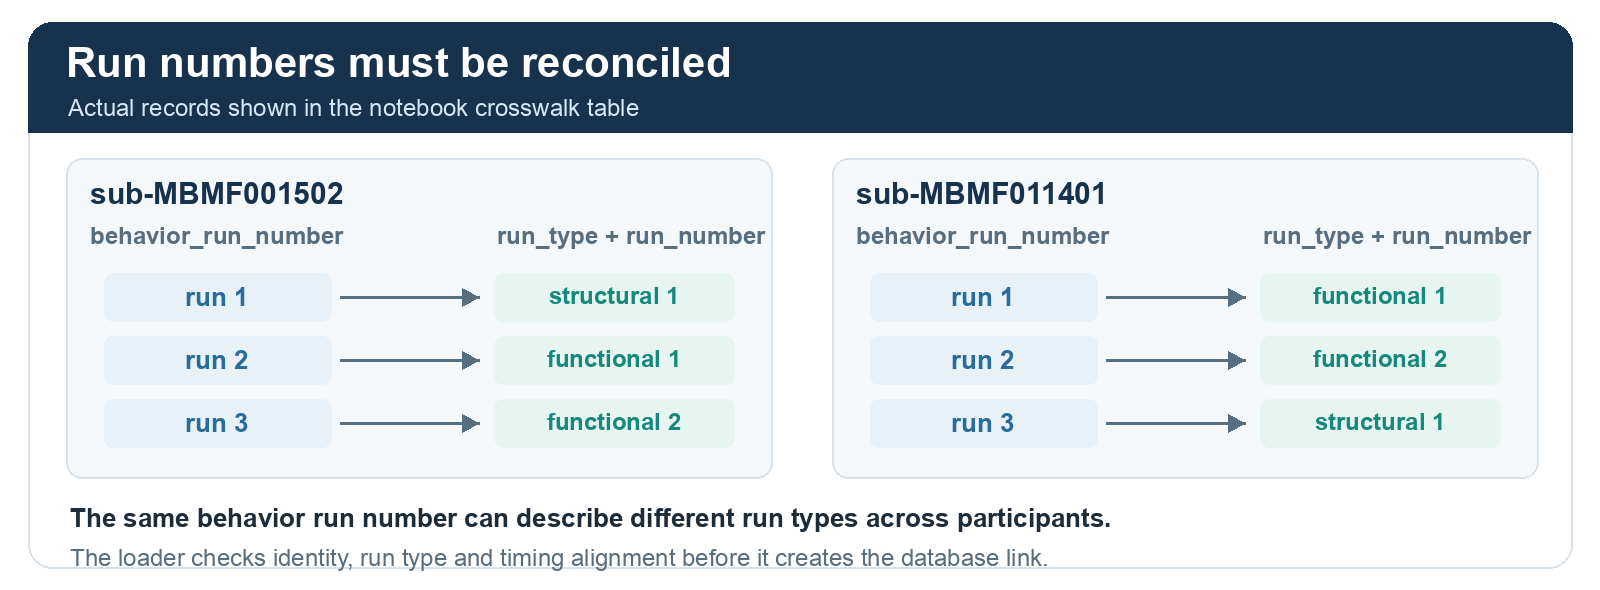


## Database structure

The core schema organizes experimental observations into participants, sessions, runs, trials and events. Task-specific attributes are stored separately, allowing the core schema to support different experimental tasks.

Foreign keys enforce relationships between records, including consistency between events and their associated trials and runs.

**Data coverage and model extension**

The core database contains behavioral and event timing data for 189 participants. Model-derived quantities were locally reproduced and validated for one pilot participant using the authors' released model code and fitted parameters.

This pilot demonstrates how computational model outputs can be integrated with observed experimental data. Additional model fits can be imported without changing the schema.

The following ER diagrams cover all 19 tables. Purple PK badges mark primary keys; teal FK badges mark foreign keys. The complete schema, including every attribute and cardinality, is available in [`sql/schema.sql`](../sql/schema.sql) and [`docs/schema.mmd`](../docs/schema.mmd).

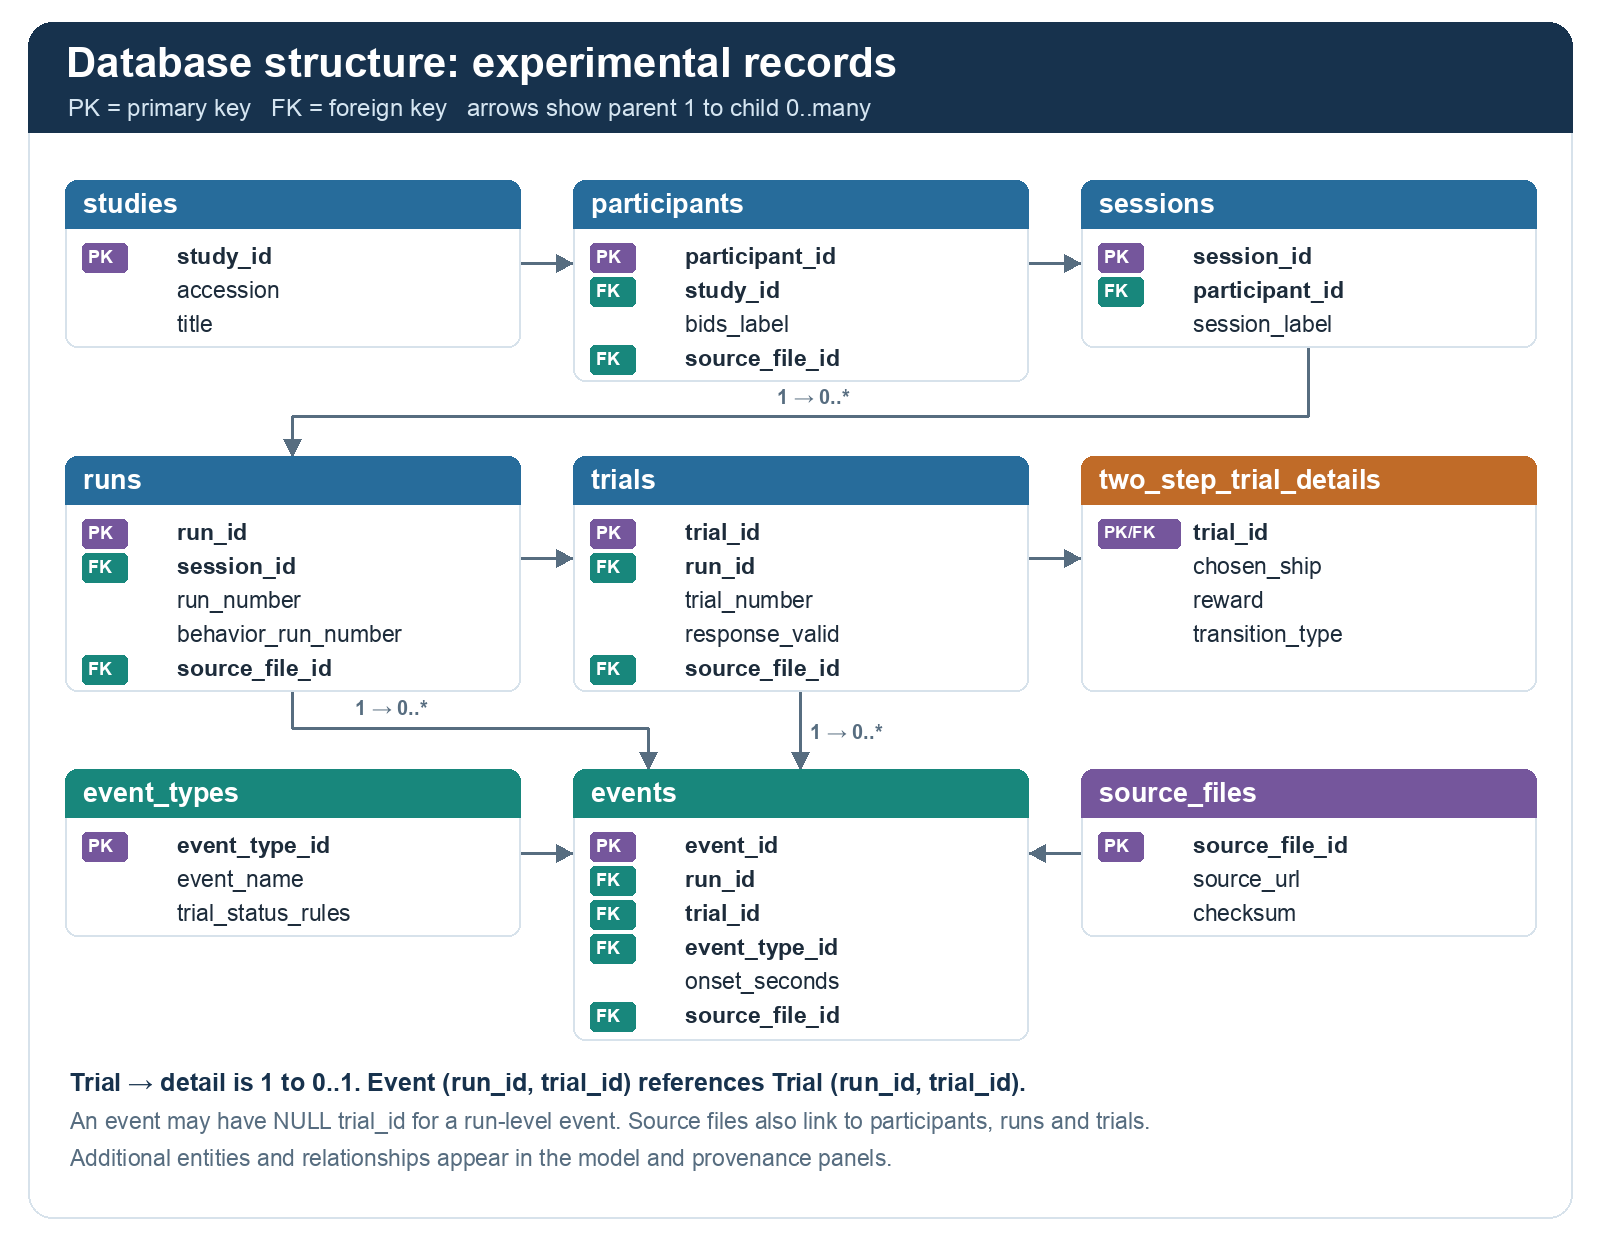

In [4]:
display(Image(filename=str(ROOT / 'docs/schema_overview.png')))

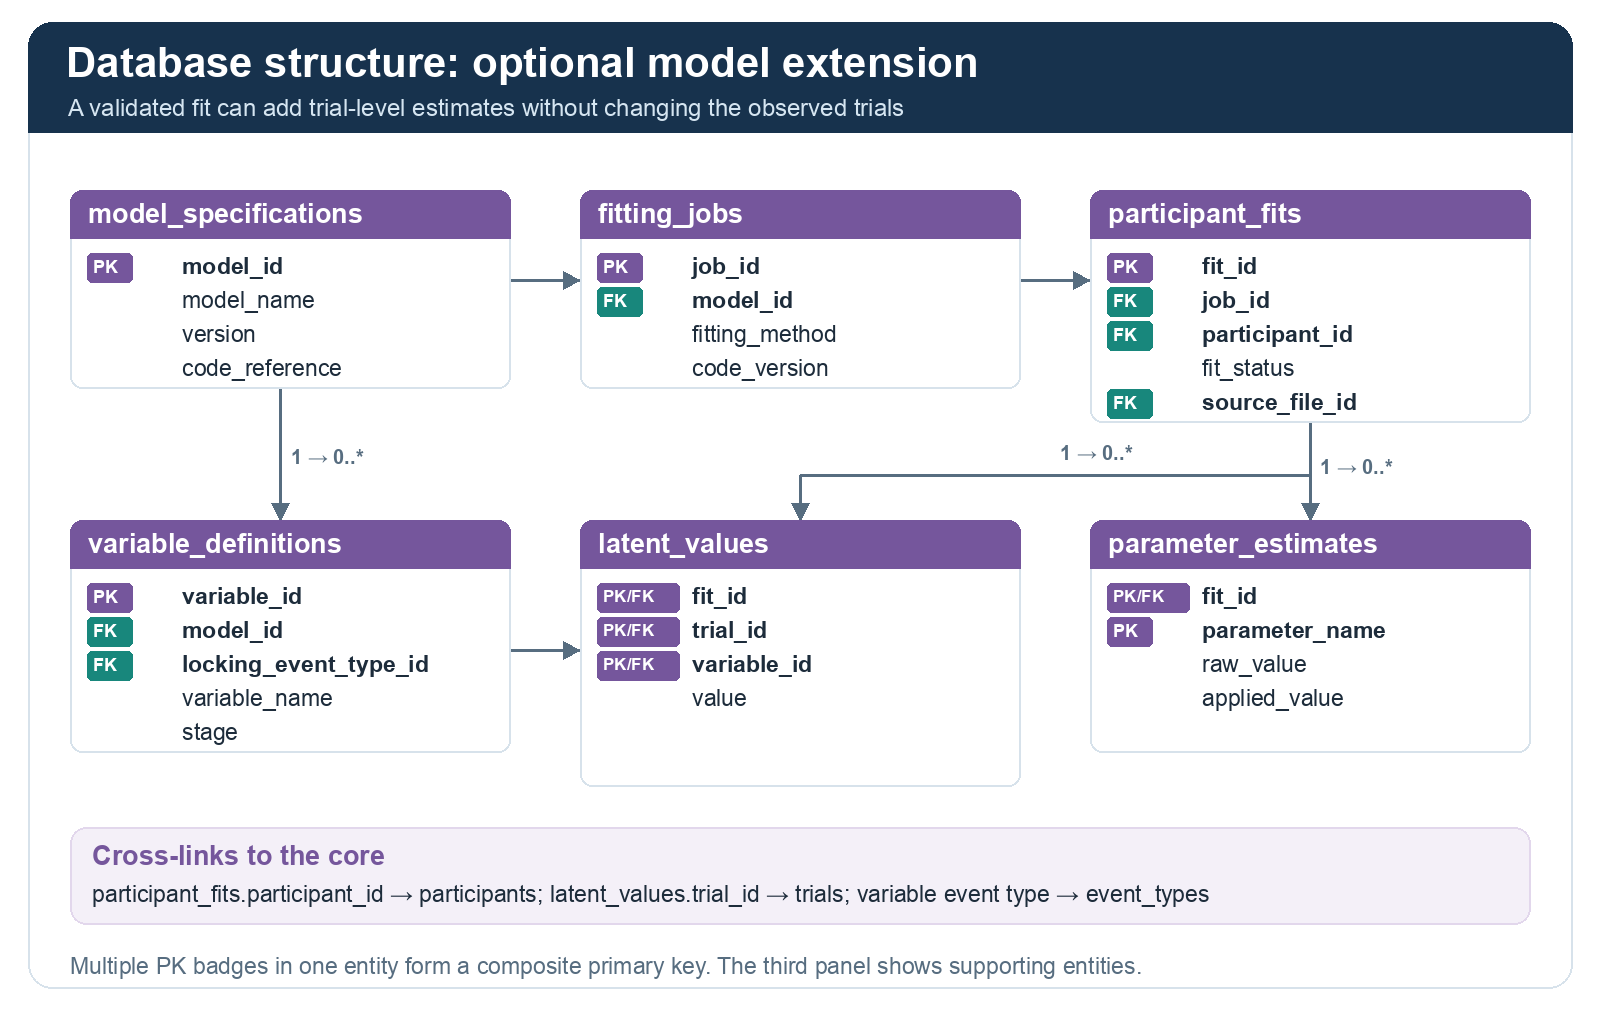


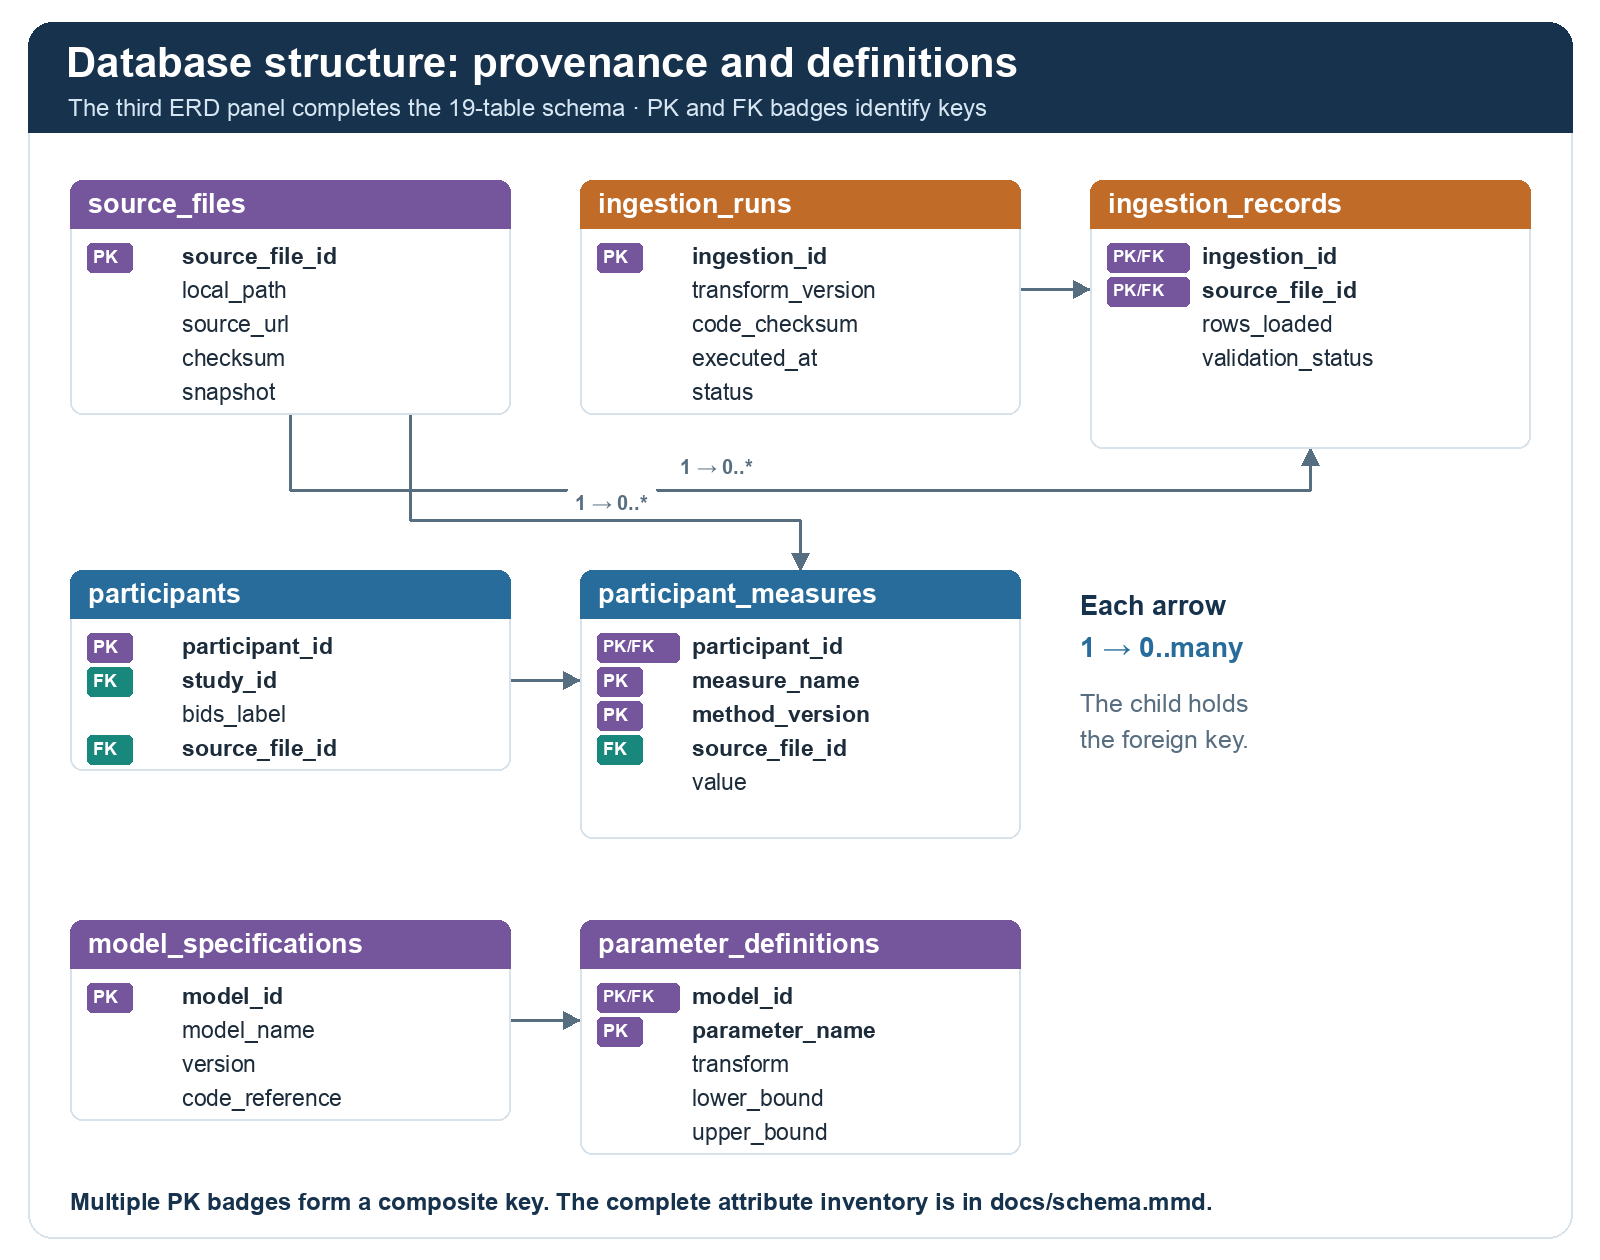


In [5]:
tables = ['participants','sessions','runs','trials','two_step_trial_details','events','latent_values','parameter_estimates','source_files']
display(pd.DataFrame([{'table': t, 'exact_rows': int(query('SELECT COUNT(*) AS n FROM '+t).iloc[0,0])} for t in tables]))
display(query("""SELECT table_name,ROUND(data_length/1024,1) AS data_KiB,ROUND(index_length/1024,1) AS index_KiB
FROM information_schema.tables WHERE table_schema='neurodb' AND table_type='BASE TABLE'
ORDER BY data_length+index_length DESC LIMIT 10"""))

,table,exact_rows
0,participants,189
1,sessions,189
2,runs,567
3,trials,48951
4,two_step_trial_details,48951
5,events,172854
6,latent_values,3870
7,parameter_estimates,12
8,source_files,760


,TABLE_NAME,data_KiB,index_KiB
0,events,16944.0,25168.0
1,trials,2576.0,5680.0
2,two_step_trial_details,3600.0,0.0
3,source_files,288.0,176.0
4,latent_values,208.0,256.0
5,ingestion_records,256.0,64.0
6,runs,48.0,32.0
7,participant_fits,16.0,48.0
8,variable_definitions,16.0,32.0
9,participants,16.0,32.0


## Interactive query application

[Open NeuroDB Explorer](http://127.0.0.1:8765/)

The standalone application provides eight predefined queries, adjustable filters, explanatory diagrams, SQL statements, execution plans and a read-only custom SQL interface.

All live query results are retrieved directly from MySQL. Run Q1 and Q3 in the explorer during the presentation; saved Q4 and Q8 outputs below provide an additional reference.

## Stay behavior

How does the previous trial's outcome relate to whether a participant repeats their choice?

The `LAG` window function retrieves information from the immediately preceding trial within the same participant and run. Missed responses are filtered afterward to avoid incorrectly pairing nonconsecutive trials.

The resulting proportions summarize all eligible trial pairs and are descriptive statistics.

,prev_reward,prev_transition,eligible_pairs,stay_count,stay_probability
0,0,common,10295,3957,0.3844
1,0,rare,4436,2876,0.6483
2,1,common,9587,8006,0.8351
3,1,rare,3352,2086,0.6223


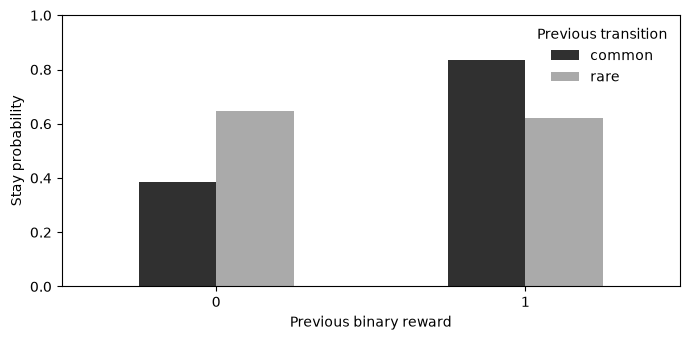

In [6]:
stay = execute('Q1')
display(stay)
fig, ax = plt.subplots(figsize=(7,3.5))
stay.pivot(index='prev_reward',columns='prev_transition',values='stay_probability').astype(float).plot.bar(ax=ax,color=['#303030','#aaaaaa'],rot=0)
ax.set(xlabel='Previous binary reward',ylabel='Stay probability',ylim=(0,1))
ax.legend(title='Previous transition',frameon=False)
plt.tight_layout(); plt.show()

## Reward and event integrity

Reward summaries first aggregate within each participant and condition, then average participant rates. This gives participants equal weight. The event audit checks types as well as total counts. The three-event pattern on a missed trial is expected, not a missing-data failure.

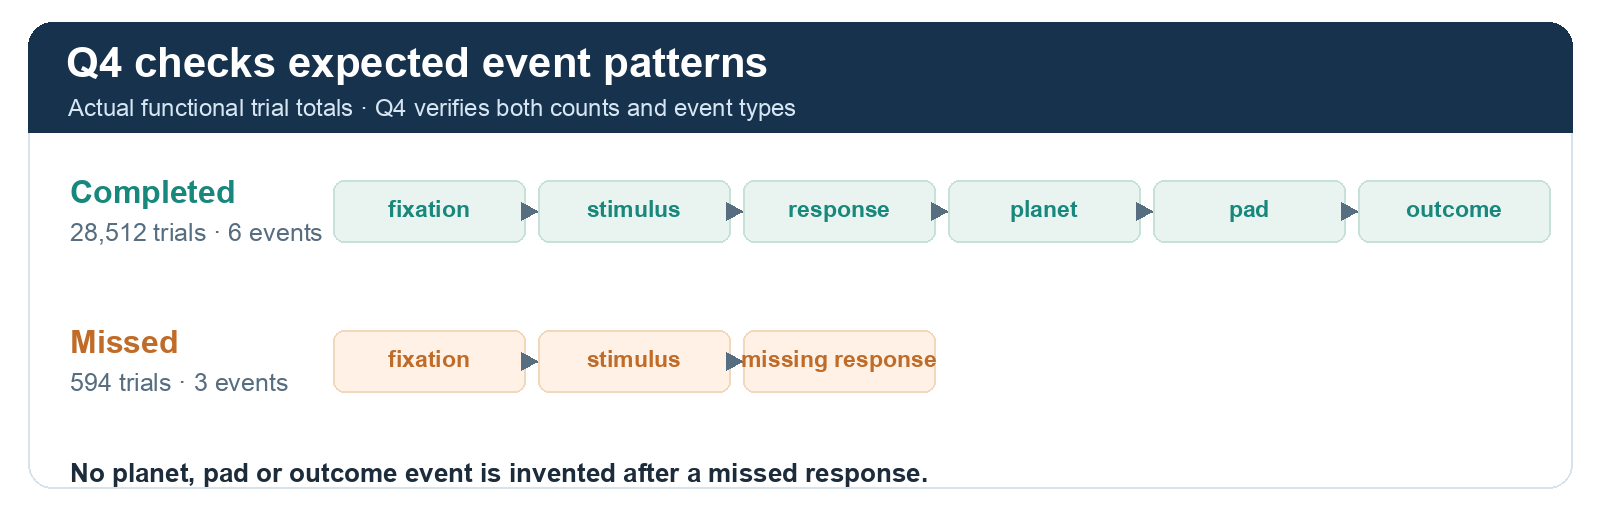


In [7]:
display(execute('Q2'))
display(execute('Q4'))

,design_variant,task_order,reward_condition,participants,valid_trials,mean_participant_reward_rate,participant_sd
0,mixed,1,1,93,6994,0.47404301,0.059712
1,mixed,1,2,93,6978,0.46327419,0.059202
2,mixed,2,1,91,6917,0.47623846,0.059534
3,mixed,2,2,91,6861,0.45750769,0.067429
4,state_only,1,1,5,385,0.45548000,0.072753
5,state_only,1,2,5,377,0.43002000,0.072273


,response_valid,event_pattern,trials,observed_events,expected_events
0,0,expected,594,1782,1782
1,1,expected,28512,171072,171072


## Ordered extraction with provenance

This query retrieves experimental events in chronological order and joins them with model-derived values when available.

Each model variable is associated with a relevant event type. `LEFT JOIN`s preserve experimental events even when no corresponding model value exists. Unavailable values remain `NULL` rather than being replaced with zero.

Source URLs, file checksums and model versions allow the extracted records to be traced back to their origins.

In [8]:
p=defaults()
display(execute('Q3',p).head(12))
extraction=execute('Q8',p)
display(extraction[['bids_label','run_number','trial_number','event_name','onset_seconds','variable_name','modulator']].head(16))
display(extraction[['behavior_source','behavior_sha256','timing_source','timing_sha256','model_version']].drop_duplicates().head())

,event_id,trial_id,trial_number,event_name,onset_seconds,duration_seconds
0,10111,2955,1,fixation,0.020575,0.0
1,10112,2955,1,stimulus,0.785154,0.0
2,10113,2955,1,response_right,1.462077,0.0
3,10114,2955,1,planet,2.936868,0.0
4,10115,2955,1,pad,4.740727,0.0
5,10116,2955,1,outcome,5.899762,0.0
6,10117,2956,2,fixation,7.442390,0.0
7,10118,2956,2,stimulus,10.490415,0.0
8,10119,2956,2,response_right,10.922577,0.0
9,10120,2956,2,planet,12.805094,0.0


,bids_label,run_number,trial_number,event_name,onset_seconds,variable_name,modulator
0,sub-MBMF001502,1,1,fixation,0.020575,NaN,NaN
1,sub-MBMF001502,1,1,stimulus,0.785154,NaN,NaN
2,sub-MBMF001502,1,1,response_right,1.462077,NaN,NaN
3,sub-MBMF001502,1,1,planet,2.936868,spe_planet,0.3
4,sub-MBMF001502,1,1,pad,4.740727,NaN,NaN
5,sub-MBMF001502,1,1,outcome,5.899762,NaN,NaN
6,sub-MBMF001502,1,2,fixation,7.442390,NaN,NaN
7,sub-MBMF001502,1,2,stimulus,10.490415,NaN,NaN
8,sub-MBMF001502,1,2,response_right,10.922577,NaN,NaN
9,sub-MBMF001502,1,2,planet,12.805094,spe_planet,0.3


,behavior_source,behavior_sha256,timing_source,timing_sha256,model_version
0,https://osf.io/download/phfw7/?version=1,7aa9a53ccaa7a9f6186b7f28d75962ec09faa2c0e3b538cc427f8991bbf198b2,https://osf.io/download/dkbc9/?version=1,166fd1a1e20c440a496bf912aecffeee1ff62b5e92af76ac0c6b994b9b5ea689,NaN
3,https://osf.io/download/phfw7/?version=1,7aa9a53ccaa7a9f6186b7f28d75962ec09faa2c0e3b538cc427f8991bbf198b2,https://osf.io/download/dkbc9/?version=1,166fd1a1e20c440a496bf912aecffeee1ff62b5e92af76ac0c6b994b9b5ea689,53dffece52606047922027eeae59745e09566844


## Physical design experiments

The archived benchmark used real observations copied into isolated event tables. The baseline retains primary, natural-key and foreign-key-supporting indexes. It is not unindexed. Alternatives add a run/onset composite index, a covering extension or reversed column order. No access hints force the optimizer.

Each comparison uses identical results, two warm-up executions and nine measurements in interleaved order. `EXPLAIN ANALYZE` runs separately from the timed query. Client timing includes result transfer; Handler counters measure handler operations, not physical disk reads.

The next cell loads the verified benchmark report so the displayed timings match the presentation figures. To intentionally refresh these machine-dependent measurements, rerun `python -m neurodb.benchmark` and rebuild the figures and saved outputs.

In [9]:
benchmark = json.loads((ROOT / 'results/benchmark.json').read_text())
measured = summary(benchmark)
display(measured.round(4))

,experiment,window_seconds,design,median_ms,handler_reads,returned_rows,selectivity
0,event window,10.0,baseline,0.6640,463,7,0.0152
1,event window,10.0,composite,0.1638,8,7,0.0152
2,event window,10.0,covering,0.1655,8,7,0.0152
3,event window,10.0,reversed,0.6340,463,7,0.0152
4,event window,60.0,baseline,0.8130,463,40,0.0866
5,event window,60.0,composite,0.3549,41,40,0.0866
6,event window,60.0,covering,0.3242,41,40,0.0866
7,event window,60.0,reversed,0.7889,463,40,0.0866
8,event window,300.0,baseline,1.5315,463,195,0.4221
9,event window,300.0,composite,1.2259,196,195,0.4221


## Event access and selectivity

Compare the baseline and composite plans for a 60-second window. Then inspect narrow and wide windows. Look for index range access, actual rows and an explicit sort. A wide interval or a small in-memory table may show little timing benefit even when fewer records are visited.

**SQL used for the 60-second event-window comparison**

```sql
SELECT event_id,run_id,trial_id,event_type_id,onset_seconds,duration_seconds
FROM bench_events_baseline
WHERE run_id=%s AND onset_seconds >= %s AND onset_seconds < %s
ORDER BY onset_seconds,event_id
```

The bound values are `(35, 0.0, 60.0)`. The composite, covering and reversed comparisons use the same statement and values, replacing only `bench_events_baseline` with their corresponding table name. Each copy contains identical event records.

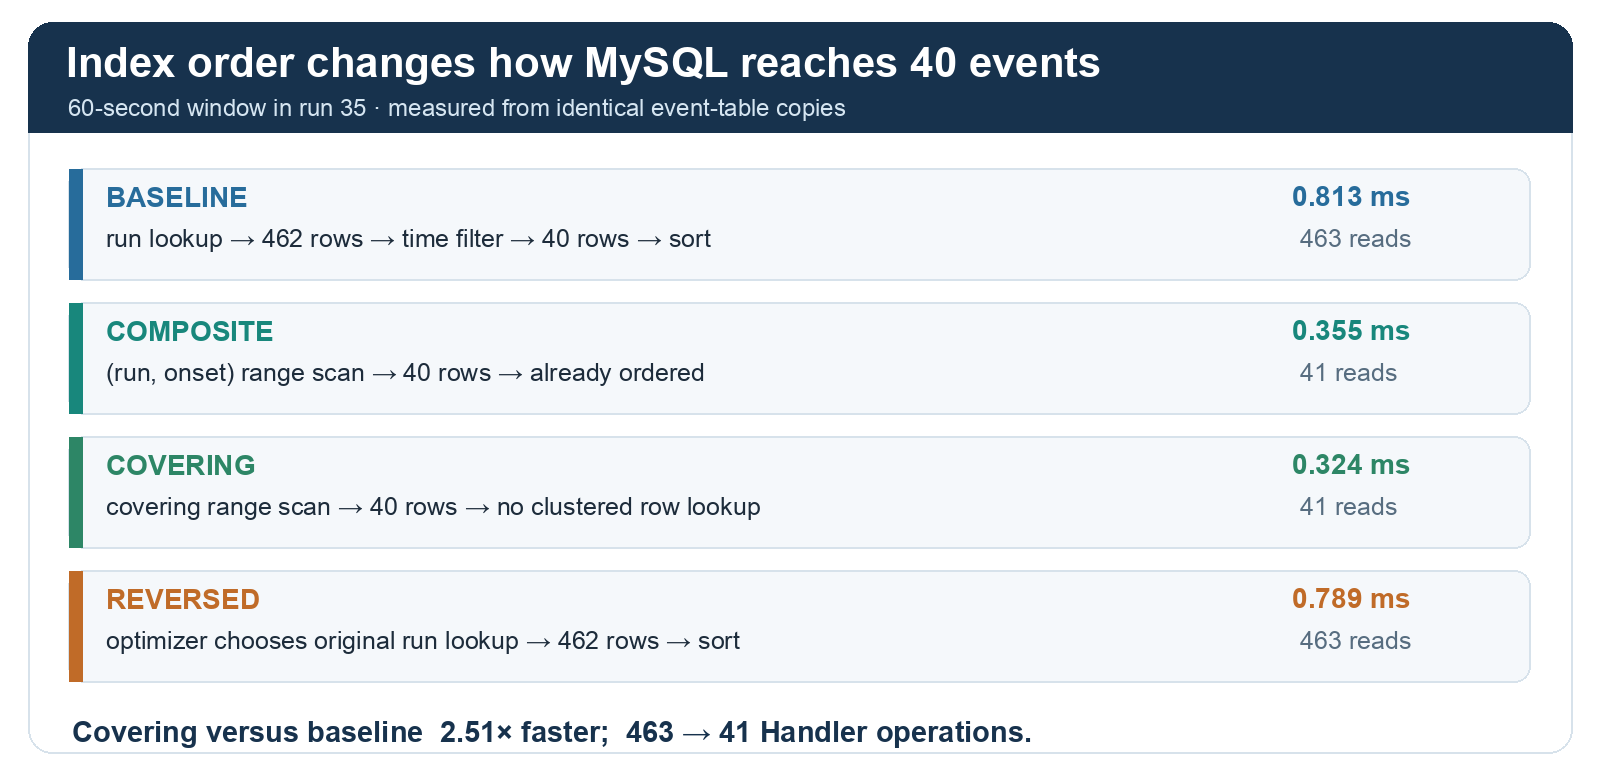


In [10]:
for name in ['baseline','composite','covering','reversed']:
    print(name.upper())
    print(benchmark['event_experiments']['60'][name]['explain_analyze'])
    print()
display(pd.DataFrame(benchmark['indexes']['production_events'])[['Key_name','Seq_in_index','Column_name','Non_unique']])

BASELINE
-> Sort: bench_events_baseline.onset_seconds, bench_events_baseline.event_id  (cost=467 rows=462) (actual time=0.521..0.523 rows=40 loops=1)
    -> Filter: ((bench_events_baseline.onset_seconds >= 0.0e0) and (bench_events_baseline.onset_seconds < 60.0e0))  (cost=467 rows=462) (actual time=0.1..0.515 rows=40 loops=1)
        -> Index lookup on bench_events_baseline using event_identity (run_id=35)  (cost=467 rows=462) (actual time=0.0997..0.488 rows=462 loops=1)


COMPOSITE
-> Index range scan on bench_events_composite using idx_events_run_onset over (run_id = 35 AND 0 <= onset_seconds < 60), with index condition: ((bench_events_composite.run_id = 35) and (bench_events_composite.onset_seconds >= 0.0e0) and (bench_events_composite.onset_seconds < 60.0e0))  (cost=49 rows=40) (actual time=0.0471..0.0507 rows=40 loops=1)


COVERING
-> Filter: ((bench_events_covering.run_id = 35) and (bench_events_covering.onset_seconds >= 0.0e0) and (bench_events_covering.onset_seconds < 60.0e0))  

,Key_name,Seq_in_index,Column_name,Non_unique
0,PRIMARY,1,event_id,0
1,event_identity,1,run_id,0
2,event_identity,2,trial_scope,0
3,event_identity,3,event_type_id,0
4,event_identity,4,event_sequence,0
5,events_trial_fk,1,run_id,1
6,events_trial_fk,2,trial_id,1
7,idx_events_run_onset,1,run_id,1
8,idx_events_run_onset,2,onset_seconds,1
9,event_type_id,1,event_type_id,1


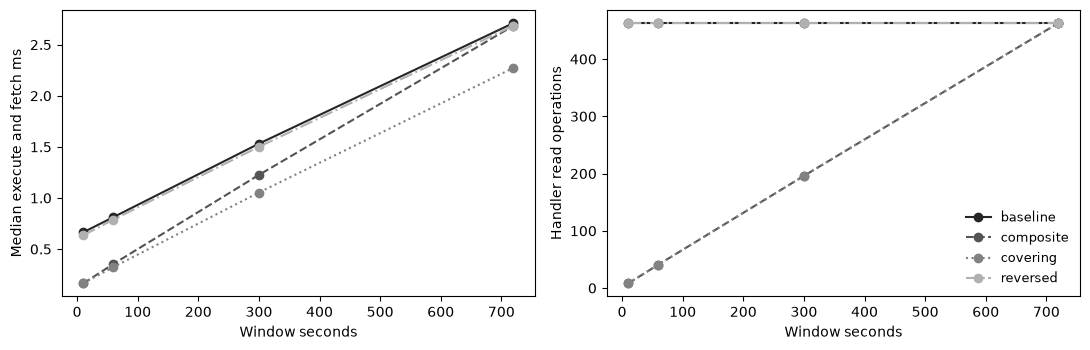

In [11]:
event_results=measured[measured.experiment=='event window']
fig,axes=plt.subplots(1,2,figsize=(11,3.6))
styles=['-','--',':','-.']
for i,(name,g) in enumerate(event_results.groupby('design',sort=False)):
    axes[0].plot(g.window_seconds,g.median_ms,styles[i],marker='o',label=name,color=str(.15+i*.18))
    axes[1].plot(g.window_seconds,g.handler_reads,styles[i],marker='o',label=name,color=str(.15+i*.18))
axes[0].set(xlabel='Window seconds',ylabel='Median execute and fetch ms')
axes[1].set(xlabel='Window seconds',ylabel='Handler read operations')
axes[1].legend(frameon=False,fontsize=9)
plt.tight_layout();plt.show()

## Cost of the extensible schema

The generic query joins the core and the task-specific detail table. The wide copy prejoins exactly the same rows and repeats participant/run attributes. Both queries return identical participant-level reward aggregates. The wide representation incurs refresh work and duplicates data; it does not replace the canonical normalized tables.

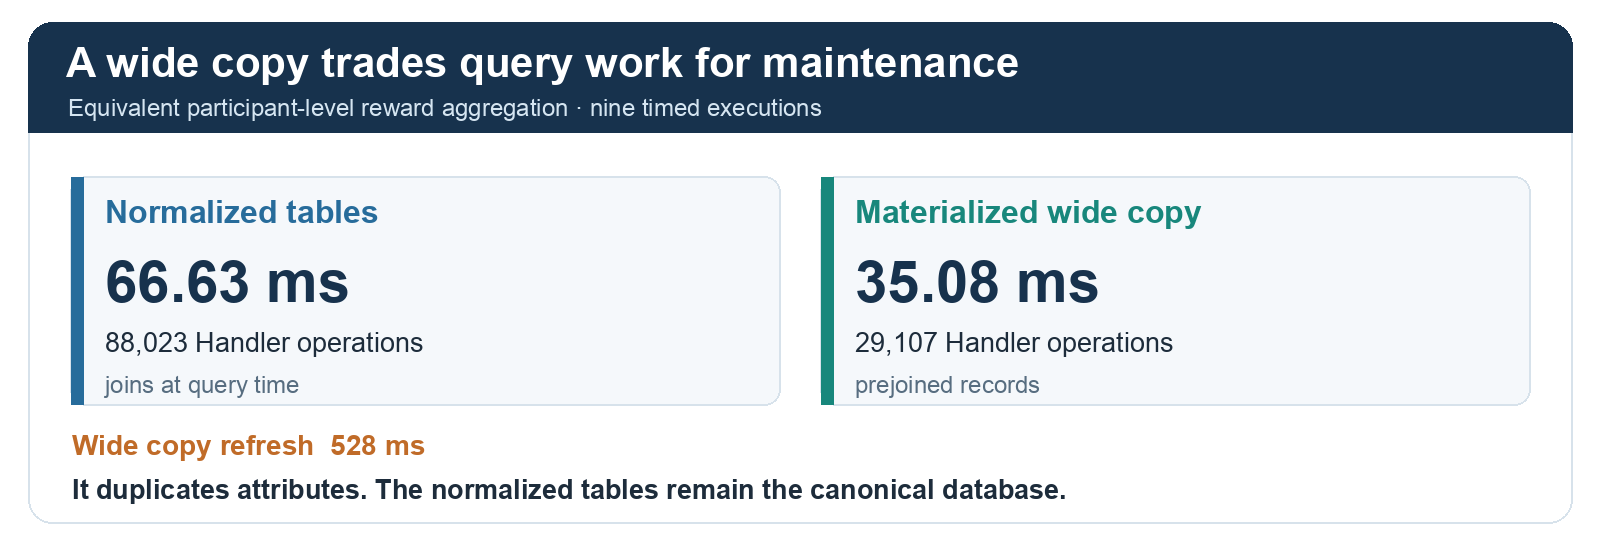


In [12]:
display(measured[measured.experiment=='behavior aggregation'].round(4))
display(pd.DataFrame([{'wide_rows':benchmark['wide_rows'],
                       'wide_serialized_MiB':benchmark['wide_serialized_json_bytes']/1024**2,
                       'wide_data_MiB':benchmark['wide_physical_storage']['DATA_LENGTH']/1024**2,
                       'wide_index_MiB':benchmark['wide_physical_storage']['INDEX_LENGTH']/1024**2,
                       'refresh_ms':benchmark['wide_refresh_ms']}]))
print(benchmark['storage_note'])
for name in ['generic_joins','wide_materialized']:
    print(name.upper());print(benchmark['extensibility'][name]['explain_analyze']);print()

,experiment,window_seconds,design,median_ms,handler_reads,returned_rows,selectivity
16,behavior aggregation,NaN,generic_joins,66.6250,88023,378,NaN
17,behavior aggregation,NaN,wide_materialized,35.0817,29107,378,NaN


,wide_rows,wide_serialized_MiB,wide_data_MiB,wide_index_MiB,refresh_ms
0,48951,27.644503,6.515625,2.515625,527.906834


Physical data and index allocation measured from a same-schema wide copy in the isolated neurodb_benchmark database after ANALYZE TABLE. The copy is removed after measurement. JSON bytes are a separate logical payload measure. Physical allocation includes page slack, not just field bytes.
GENERIC_JOINS
-> Sort: trial_context.participant_id, trial_context.reward_condition  (actual time=93.8..93.9 rows=378 loops=1)
    -> Table scan on <temporary>  (actual time=93.7..93.8 rows=378 loops=1)
        -> Aggregate using temporary table  (actual time=93.7..93.7 rows=378 loops=1)
            -> Nested loop inner join  (cost=9704 rows=2479) (actual time=0.112..75.4 rows=28512 loops=1)
                -> Nested loop inner join  (cost=8836 rows=2479) (actual time=0.107..36.5 rows=28512 loops=1)
                    -> Nested loop inner join  (cost=161 rows=284) (actual time=0.0329..0.822 rows=378 loops=1)
                        -> Nested loop inner join  (cost=85.3 rows=189) (actual time=0.0288..

## Pilot model integration

Q5 and Q6 demonstrate how computational model outputs can be queried alongside observed behavior.

The current model extension contains validated outputs for one pilot participant. Q5 compares prediction errors across transition types. Q6 compares action preferences estimated by two computational mechanisms.

These queries demonstrate relational integration and consistency of model-derived data rather than population-level scientific findings.

In [13]:
display(execute('Q5'))
display(execute('Q6'))

,bids_label,transition_type,trials,mean_stage_one_spe
0,sub-MBMF001502,common,112,0.3
1,sub-MBMF001502,rare,41,0.7


,bids_label,fit_id,comparable_trials,opposite_sign_trials,trials_with_ties,conflict_fraction
0,sub-MBMF001502,1,153,78,2,0.5098


## Final integrity gate

The final checks cover source checksums, foreign-key consistency, trial/event patterns, pilot counts, model ownership and an independent implementation of the stay query. The source cohort, validated database cohort and published analytic cohort are separate denominators. No voxel data or new fMRI inference are included.

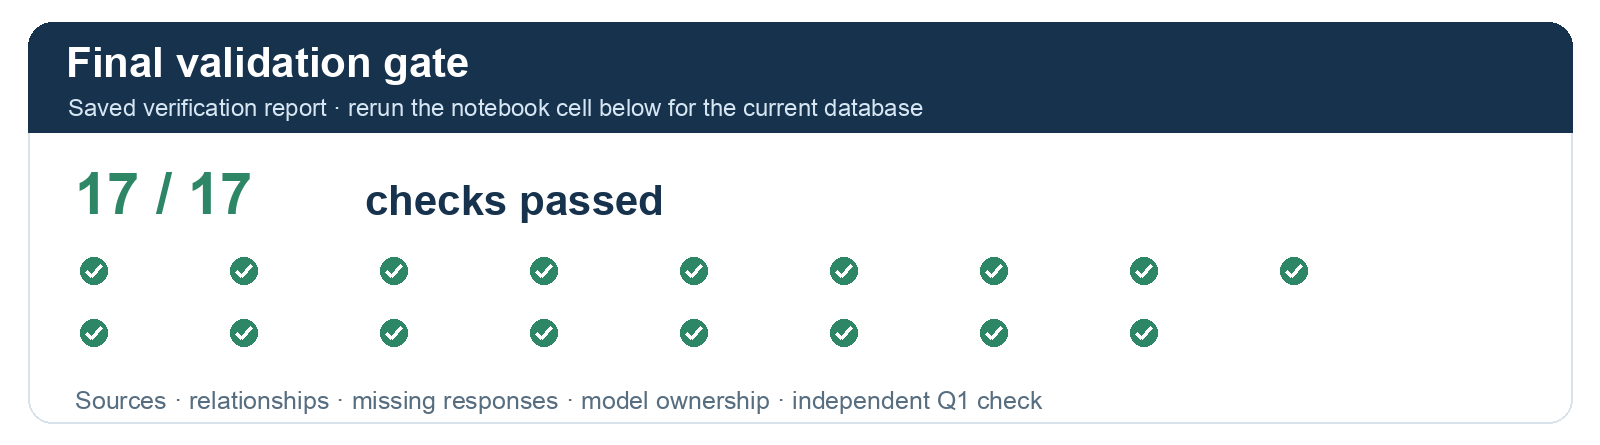


In [14]:
from neurodb.validate import validate
validation=validate()
display(pd.DataFrame([{'check':k,'passed':v} for k,v in validation['checks'].items()]))
assert validation['passed']
print('All database validation gates passed.')

,check,passed
0,mysql_84,True
1,minimum_30_validated,True
2,one_detail_per_trial,True
3,event_run_consistency,True
4,events_within_task_run,True
5,fit_trial_participant_consistency,True
6,fit_variable_model_consistency,True
7,parameter_definition_consistency,True
8,no_latents_on_missed_trials,True
9,no_imputed_missed_outcomes,True


All database validation gates passed.


## Reference materials

| Material | Location |
| --- | --- |
| Classroom speaking guide | `docs/DEMO_GUIDE.md` |
| Source mapping and limitations | `docs/DATA_DICTIONARY.md` |
| Executable relational schema | `sql/schema.sql` |
| Saved plans and measurements | `results/benchmark.json` |
| Load and validation audit | `results/validation.json` |
| MySQL execution plan reference | https://dev.mysql.com/doc/refman/8.4/en/explain.html |
| Public observations | https://osf.io/ctfzd/ |
| OpenNeuro snapshot | https://openneuro.org/datasets/ds007474/versions/1.0.5 |